# Analyse de sentiments — Reproduction de l'article, MLP et DistilBERT

**Article de référence :** Xinya Liao, *Sentiment Analysis Based on Machine Learning Models* (2024).

Ce notebook suit quatre étapes :
1. **Reproduction** de l'article : SST-2, prétraitement (minuscules, tokenisation, stopwords NLTK, stemming de Porter), TF-IDF, KNN, Random Forest, Multinomial Naive Bayes et Logistic Regression, évalués sur SST-2 et IMDB.
2. **Nouvelle approche 1 : MLP sur TF-IDF** (même représentation que les 4 modèles → comparaison contrôlée).
3. **Nouvelle approche 2 : DistilBERT fine-tuné** (représentation contextuelle, texte brut → comparaison non contrôlée sur la représentation).
4. **Comparaison statistique** (test de McNemar exact avec correction de Holm), analyse de phrases contrôlées et temps d'entraînement.

> Les scores de l'article sont des résultats publiés. Les scores de ce notebook sont nos résultats de reproduction ; ils peuvent varier légèrement (versions des bibliothèques, détails non précisés dans l'article).

> **Avant de lancer :** activer un GPU dans Colab (*Exécution → Modifier le type d'exécution → T4 GPU*). Sans GPU, la section DistilBERT est très lente.

## 0. Installation des dépendances

In [ ]:
!pip -q install datasets transformers accelerate statsmodels nltk scikit-learn pandas matplotlib seaborn joblib

## 1. Imports et configuration

In [2]:
import re
import time
import random
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import torch

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize
from datasets import load_dataset, Dataset
from scipy.stats import binomtest
from statsmodels.stats.multitest import multipletests

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    DataCollatorWithPadding, Trainer, TrainingArguments, set_seed
)

for resource in ["punkt", "punkt_tab", "stopwords"]:
    nltk.download(resource, quiet=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
set_seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Appareil :", DEVICE)
if DEVICE == "cpu":
    print("ATTENTION : pas de GPU. Activer un GPU T4 dans Colab avant la section DistilBERT.")

Appareil : cuda


## 2. Chargement des données

L'article utilise 67 349 phrases de SST-2 : 50 000 pour l'entraînement et les 17 349 restantes pour le test. Il utilise aussi 10 000 critiques IMDB comme données de test externes.

Nous ajoutons un troisième jeu de test : la **validation officielle de SST-2** (872 phrases complètes). Le split aléatoire du train contient des phrases *et* leurs sous-phrases : un fragment du test peut avoir des fragments voisins dans le train, ce qui rend le score « SST-2 » optimiste. La validation officielle n'a pas ce problème.

Étiquettes : `0 = négatif`, `1 = positif`.

In [3]:
sst = load_dataset("stanfordnlp/sst2", split="train").to_pandas()[["sentence", "label"]]
sst = sst.sample(frac=1, random_state=SEED).reset_index(drop=True)

if len(sst) < 67349:
    raise ValueError(f"Le split SST-2 contient {len(sst)} lignes, 67 349 sont attendues.")

sst = sst.iloc[:67349].copy()
train_df = sst.iloc[:50000].copy()
test_df = sst.iloc[50000:67349].copy()

sst_val = load_dataset("stanfordnlp/sst2", split="validation").to_pandas()[["sentence", "label"]]

imdb = load_dataset("stanfordnlp/imdb", split="test").to_pandas()[["text", "label"]]
imdb = imdb.sample(n=10000, random_state=SEED).reset_index(drop=True)

print("SST-2 entraînement :", len(train_df))
print("SST-2 test (split aléatoire) :", len(test_df))
print("SST-2 validation officielle :", len(sst_val))
print("IMDB test externe :", len(imdb))

print("\nPart de la classe positive :")
print(f"  SST-2 train : {train_df['label'].mean():.3f}")
print(f"  SST-2 test  : {test_df['label'].mean():.3f}")
print(f"  SST-2 val.  : {sst_val['label'].mean():.3f}")
print(f"  IMDB        : {imdb['label'].mean():.3f}")

README.md:   0%|          | 0.00/5.27k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  148kB            

... (11 outputs left out)

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

SST-2 entraînement : 50000
SST-2 test (split aléatoire) : 17349
SST-2 validation officielle : 872
IMDB test externe : 10000

Part de la classe positive :
  SST-2 train : 0.560
  SST-2 test  : 0.553
  SST-2 val.  : 0.509
  IMDB        : 0.496


## 3. Prétraitement de l'article

Étapes décrites dans l'article : minuscules → tokenisation → suppression des stopwords (liste NLTK) → stemming (Porter). Seuls les tokens alphabétiques sont conservés (`isalpha()`), donc `not`, `n't` et les emojis disparaissent. Ce prétraitement est utilisé pour les 4 modèles de l'article **et** pour le MLP (comparaison contrôlée).

DistilBERT utilisera le **texte brut** : son tokenizer et son pré-entraînement supposent un texte non transformé (pas de stemming ni de retrait de stopwords).

In [4]:
stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

def preprocess_original(text):
    text = re.sub(r"<br\s*/?>", " ", str(text).lower())
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t.isalpha() and t not in stop_words]
    return " ".join(stemmer.stem(t) for t in tokens)

train_df["clean"] = train_df["sentence"].apply(preprocess_original)
test_df["clean"] = test_df["sentence"].apply(preprocess_original)
sst_val["clean"] = sst_val["sentence"].apply(preprocess_original)
imdb["clean"] = imdb["text"].apply(preprocess_original)

display(train_df[["sentence", "clean", "label"]].head())

,sentence,clean,label
0,with outtakes in which most of the characters ...,outtak charact forget line utter uhhh better w...,0
1,enigma is well-made,enigma,1
2,is ) so stoked to make an important film about...,stoke make import film human infidel happenst ...,0
3,the closest thing to the experience of space t...,closest thing experi space travel,1
4,lose their luster,lose luster,0


## 4. Représentation TF-IDF

Le vectoriseur est ajusté uniquement sur le train SST-2, puis appliqué aux trois jeux de test.

In [5]:
tfidf_original = TfidfVectorizer()
X_train = tfidf_original.fit_transform(train_df["clean"])
y_train = train_df["label"].astype(int).values

# Jeux d'évaluation : mêmes clés partout dans le notebook.
X_by_set = {
    "SST-2":      tfidf_original.transform(test_df["clean"]),
    "SST-2 val.": tfidf_original.transform(sst_val["clean"]),
    "IMDB":       tfidf_original.transform(imdb["clean"]),
}
Y = {
    "SST-2":      test_df["label"].astype(int).values,
    "SST-2 val.": sst_val["label"].astype(int).values,
    "IMDB":       imdb["label"].astype(int).values,
}
# Texte brut pour DistilBERT (les <br /> d'IMDB sont retirés, rien d'autre).
RAW = {
    "SST-2":      test_df["sentence"].tolist(),
    "SST-2 val.": sst_val["sentence"].tolist(),
    "IMDB":       imdb["text"].str.replace(r"<br\s*/?>", " ", regex=True).tolist(),
}

print("TF-IDF entraînement :", X_train.shape)
for k, v in X_by_set.items():
    print(f"TF-IDF {k} :", v.shape)

TF-IDF entraînement : (50000, 9211)
TF-IDF SST-2 : (17349, 9211)
TF-IDF SST-2 val. : (872, 9211)
TF-IDF IMDB : (10000, 9211)


## 5. Fonctions d'évaluation

Précision, rappel et F1 sont calculés avec une moyenne pondérée (c'est ce qui rend rappel = accuracy, comme dans le tableau de l'article). Les prédictions de chaque modèle sont stockées pour les tests statistiques.

In [6]:
preds = {}     # (modèle, jeu) -> prédictions
timings = {}   # modèle -> temps d'entraînement (secondes)

def metrics(y, pred):
    p, r, f, _ = precision_recall_fscore_support(y, pred, average="weighted", zero_division=0)
    return {"Accuracy": accuracy_score(y, pred), "Precision": p, "Recall": r, "F1-score": f}

def register_sklearn(name, model):
    for ds, X in X_by_set.items():
        preds[(name, ds)] = model.predict(X)

def results_table(names):
    rows = []
    for n in names:
        for ds in Y:
            rows.append({"Model": n, "Dataset": ds, **metrics(Y[ds], preds[(n, ds)])})
    return pd.DataFrame(rows)

## 6. Reproduction : les 4 modèles de l'article

- **KNN** : `n_neighbors=5`
- **Random Forest** : 8 arbres, `bootstrap=True`
- **Multinomial Naive Bayes**
- **Logistic Regression** : `max_iter=1000`

In [7]:
models_article = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(n_estimators=8, bootstrap=True, random_state=SEED, n_jobs=-1),
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
}

for name, model in models_article.items():
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    timings[name] = time.perf_counter() - t0
    register_sklearn(name, model)
    print(f"{name} : entraîné en {timings[name]:.1f} s")

KNN : entraîné en 0.0 s
Random Forest : entraîné en 14.4 s
Naive Bayes : entraîné en 0.0 s
Logistic Regression : entraîné en 0.4 s


### 6.1 Résultats de la reproduction et comparaison avec l'article

In [8]:
ARTICLE_MODELS = list(models_article)
results_reproduction = results_table(ARTICLE_MODELS)

article_results = pd.DataFrame([
    ["KNN", "SST-2", 0.88, 0.88, 0.88, 0.87],
    ["KNN", "IMDB", 0.50, 0.54, 0.50, 0.35],
    ["Random Forest", "SST-2", 0.89, 0.89, 0.89, 0.89],
    ["Random Forest", "IMDB", 0.67, 0.68, 0.67, 0.67],
    ["Naive Bayes", "SST-2", 0.87, 0.87, 0.87, 0.87],
    ["Naive Bayes", "IMDB", 0.80, 0.80, 0.80, 0.80],
    ["Logistic Regression", "SST-2", 0.88, 0.88, 0.88, 0.88],
    ["Logistic Regression", "IMDB", 0.81, 0.81, 0.81, 0.81],
], columns=["Model", "Dataset", "Accuracy", "Precision", "Recall", "F1-score"])

print("Notre reproduction (3 jeux de test) :")
display(results_reproduction.round(3))

print("Reproduction vs article (SST-2 split aléatoire et IMDB uniquement, comme dans l'article) :")
comparison_article = results_reproduction.merge(
    article_results, on=["Model", "Dataset"], suffixes=(" (repro)", " (article)")
)
display(comparison_article.round(3))

Notre reproduction (3 jeux de test) :


,Model,Dataset,Accuracy,Precision,Recall,F1-score
0,KNN,SST-2,0.875,0.874,0.875,0.875
1,KNN,SST-2 val.,0.553,0.552,0.553,0.552
2,KNN,IMDB,0.507,0.507,0.507,0.506
3,Random Forest,SST-2,0.890,0.890,0.890,0.890
4,Random Forest,SST-2 val.,0.729,0.729,0.729,0.729
5,Random Forest,IMDB,0.670,0.678,0.670,0.666
6,Naive Bayes,SST-2,0.865,0.866,0.865,0.864
7,Naive Bayes,SST-2 val.,0.779,0.786,0.779,0.777
8,Naive Bayes,IMDB,0.799,0.802,0.799,0.798
9,Logistic Regression,SST-2,0.869,0.869,0.869,0.868


Reproduction vs article (SST-2 split aléatoire et IMDB uniquement, comme dans l'article) :


,Model,Dataset,Accuracy (repro),Precision (repro),Recall (repro),F1-score (repro),Accuracy (article),Precision (article),Recall (article),F1-score (article)
0,KNN,SST-2,0.875,0.874,0.875,0.875,0.88,0.88,0.88,0.87
1,KNN,IMDB,0.507,0.507,0.507,0.506,0.50,0.54,0.50,0.35
2,Random Forest,SST-2,0.890,0.890,0.890,0.890,0.89,0.89,0.89,0.89
3,Random Forest,IMDB,0.670,0.678,0.670,0.666,0.67,0.68,0.67,0.67
4,Naive Bayes,SST-2,0.865,0.866,0.865,0.864,0.87,0.87,0.87,0.87
5,Naive Bayes,IMDB,0.799,0.802,0.799,0.798,0.80,0.80,0.80,0.80
6,Logistic Regression,SST-2,0.869,0.869,0.869,0.868,0.88,0.88,0.88,0.88
7,Logistic Regression,IMDB,0.810,0.810,0.810,0.810,0.81,0.81,0.81,0.81


### 6.2 Diagnostic : part de prédictions positives

Dans l'article, le F1 du KNN sur IMDB (0,35) pour une accuracy de 0,50 suggère un modèle qui prédit presque toujours la même classe. Ce tableau permet de le vérifier directement (la vraie part de positifs figure sur la dernière ligne).

In [9]:
dist = pd.DataFrame({ds: {n: preds[(n, ds)].mean() for n in ARTICLE_MODELS} for ds in Y})
dist.loc["(vraie part de positifs)"] = [Y[ds].mean() for ds in Y]
display(dist.round(3))

,SST-2,SST-2 val.,IMDB
KNN,0.558,0.537,0.548
Random Forest,0.567,0.514,0.388
Naive Bayes,0.590,0.591,0.442
Logistic Regression,0.576,0.584,0.472
(vraie part de positifs),0.553,0.509,0.496


## 7. Nouvelle approche 1 — MLP sur TF-IDF

Un perceptron multicouche (1 couche cachée de 256 neurones, ReLU) sur **la même matrice TF-IDF** que les 4 modèles de l'article. Seul le classifieur change : la comparaison est donc contrôlée.

Les hyperparamètres ne viennent pas de l'article (qui n'en parle pas) : ils sont fixés a priori, sans réglage sur les jeux de test. L'arrêt anticipé utilise 10 % du train ; comme ce sont des phrases/sous-phrases tirées au hasard, ce critère est lui aussi légèrement optimiste, mais il ne sert qu'à décider quand arrêter l'entraînement.

In [10]:
mlp = MLPClassifier(
    hidden_layer_sizes=(256,), activation="relu", alpha=1e-4,
    batch_size=256, learning_rate_init=1e-3, max_iter=30,
    early_stopping=True, validation_fraction=0.1, n_iter_no_change=3,
    random_state=SEED
)

t0 = time.perf_counter()
mlp.fit(X_train, y_train)
timings["MLP (TF-IDF)"] = time.perf_counter() - t0
register_sklearn("MLP (TF-IDF)", mlp)

print(f"MLP entraîné en {timings['MLP (TF-IDF)']:.1f} s, {mlp.n_iter_} époques")
print(f"Meilleur score de validation interne : {mlp.best_validation_score_:.3f}")
display(results_table(["MLP (TF-IDF)"]).round(3))

MLP entraîné en 198.1 s, 20 époques
Meilleur score de validation interne : 0.895


,Model,Dataset,Accuracy,Precision,Recall,F1-score
0,MLP (TF-IDF),SST-2,0.895,0.894,0.895,0.894
1,MLP (TF-IDF),SST-2 val.,0.760,0.763,0.760,0.759
2,MLP (TF-IDF),IMDB,0.768,0.776,0.768,0.766


## 8. Nouvelle approche 2 — DistilBERT fine-tuné

`distilbert-base-uncased` est fine-tuné sur **les mêmes 50 000 phrases** SST-2 (2 époques, lr 2e-5, batch 32). Il lit le texte brut : sa tokenisation en sous-mots et ses représentations contextuelles lui permettent de voir « not good » dans son contexte, sans astuce de prétraitement.

Choix à signaler dans le compte rendu :
- La représentation change aussi (texte brut, pas de stemming/stopwords) : l'écart avec les autres modèles combine classifieur **et** représentation.
- Les phrases SST-2 sont tronquées à 128 tokens, les critiques IMDB à **256 tokens** (le début de la critique est conservé, la fin est perdue).
- Le modèle de départ a été pré-entraîné sur du texte général (dont des textes proches d'IMDB) : il apporte des connaissances que les modèles TF-IDF n'ont pas.

In [11]:
MODEL_NAME = "distilbert-base-uncased"
MAX_LEN = {"SST-2": 128, "SST-2 val.": 128, "IMDB": 256}

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def to_hf(texts, labels, max_len):
    ds = Dataset.from_dict({"text": list(texts), "labels": [int(l) for l in labels]})
    return ds.map(lambda b: tokenizer(b["text"], truncation=True, max_length=max_len),
                  batched=True, remove_columns=["text"])

train_ds = to_hf(train_df["sentence"], train_df["label"], 128)

model_bert = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)

training_args = TrainingArguments(
    output_dir="/content/distilbert_sst2",
    num_train_epochs=2,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=128,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=200,
    fp16=(DEVICE == "cuda"),
    logging_steps=200,
    save_strategy="no",
    report_to="none",
    seed=SEED,
)

trainer = Trainer(
    model=model_bert,
    args=training_args,
    train_dataset=train_ds,
    data_collator=DataCollatorWithPadding(tokenizer),
)

t0 = time.perf_counter()
trainer.train()
timings["DistilBERT"] = time.perf_counter() - t0
print(f"DistilBERT entraîné en {timings['DistilBERT']:.0f} s")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/50000 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
200,0.516213
400,0.286125
600,0.251643
800,0.232046
1000,0.210057
1200,0.209429
1400,0.200921
1600,0.182205
1800,0.124971
2000,0.138067


DistilBERT entraîné en 135 s


In [12]:
for ds in Y:
    eval_ds = to_hf(RAW[ds], Y[ds], MAX_LEN[ds])
    logits = trainer.predict(eval_ds).predictions
    preds[("DistilBERT", ds)] = logits.argmax(axis=-1)

display(results_table(["DistilBERT"]).round(3))

Map:   0%|          | 0/17349 [00:00<?, ? examples/s]

Map:   0%|          | 0/872 [00:00<?, ? examples/s]

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

,Model,Dataset,Accuracy,Precision,Recall,F1-score
0,DistilBERT,SST-2,0.945,0.945,0.945,0.945
1,DistilBERT,SST-2 val.,0.913,0.913,0.913,0.913
2,DistilBERT,IMDB,0.876,0.877,0.876,0.876


## 9. Comparaison globale

In [ ]:
ALL_MODELS = ARTICLE_MODELS + ["MLP (TF-IDF)", "DistilBERT"]
results_all = results_table(ALL_MODELS)

print("Accuracy par modèle et jeu de test")
display(results_all.pivot_table(index="Model", columns="Dataset", values="Accuracy", sort=False)[list(Y)].round(3))

print("F1-score (pondéré) par modèle et jeu de test")
display(results_all.pivot_table(index="Model", columns="Dataset", values="F1-score", sort=False)[list(Y)].round(3))

g = sns.catplot(
    data=results_all, x="Model", y="F1-score", col="Dataset", col_order=list(Y),
    kind="bar", errorbar=None, height=4.5, aspect=1.2
)
g.set(ylim=(0.4, 1.0))   # axe tronqué : lire comme un zoom
g.set_xticklabels(rotation=35, ha="right")
g.set_titles("{col_name}")
g.figure.suptitle("F1-score pondéré par modèle et par jeu de test", y=1.03)
plt.show()

### 9.1 Matrices de confusion

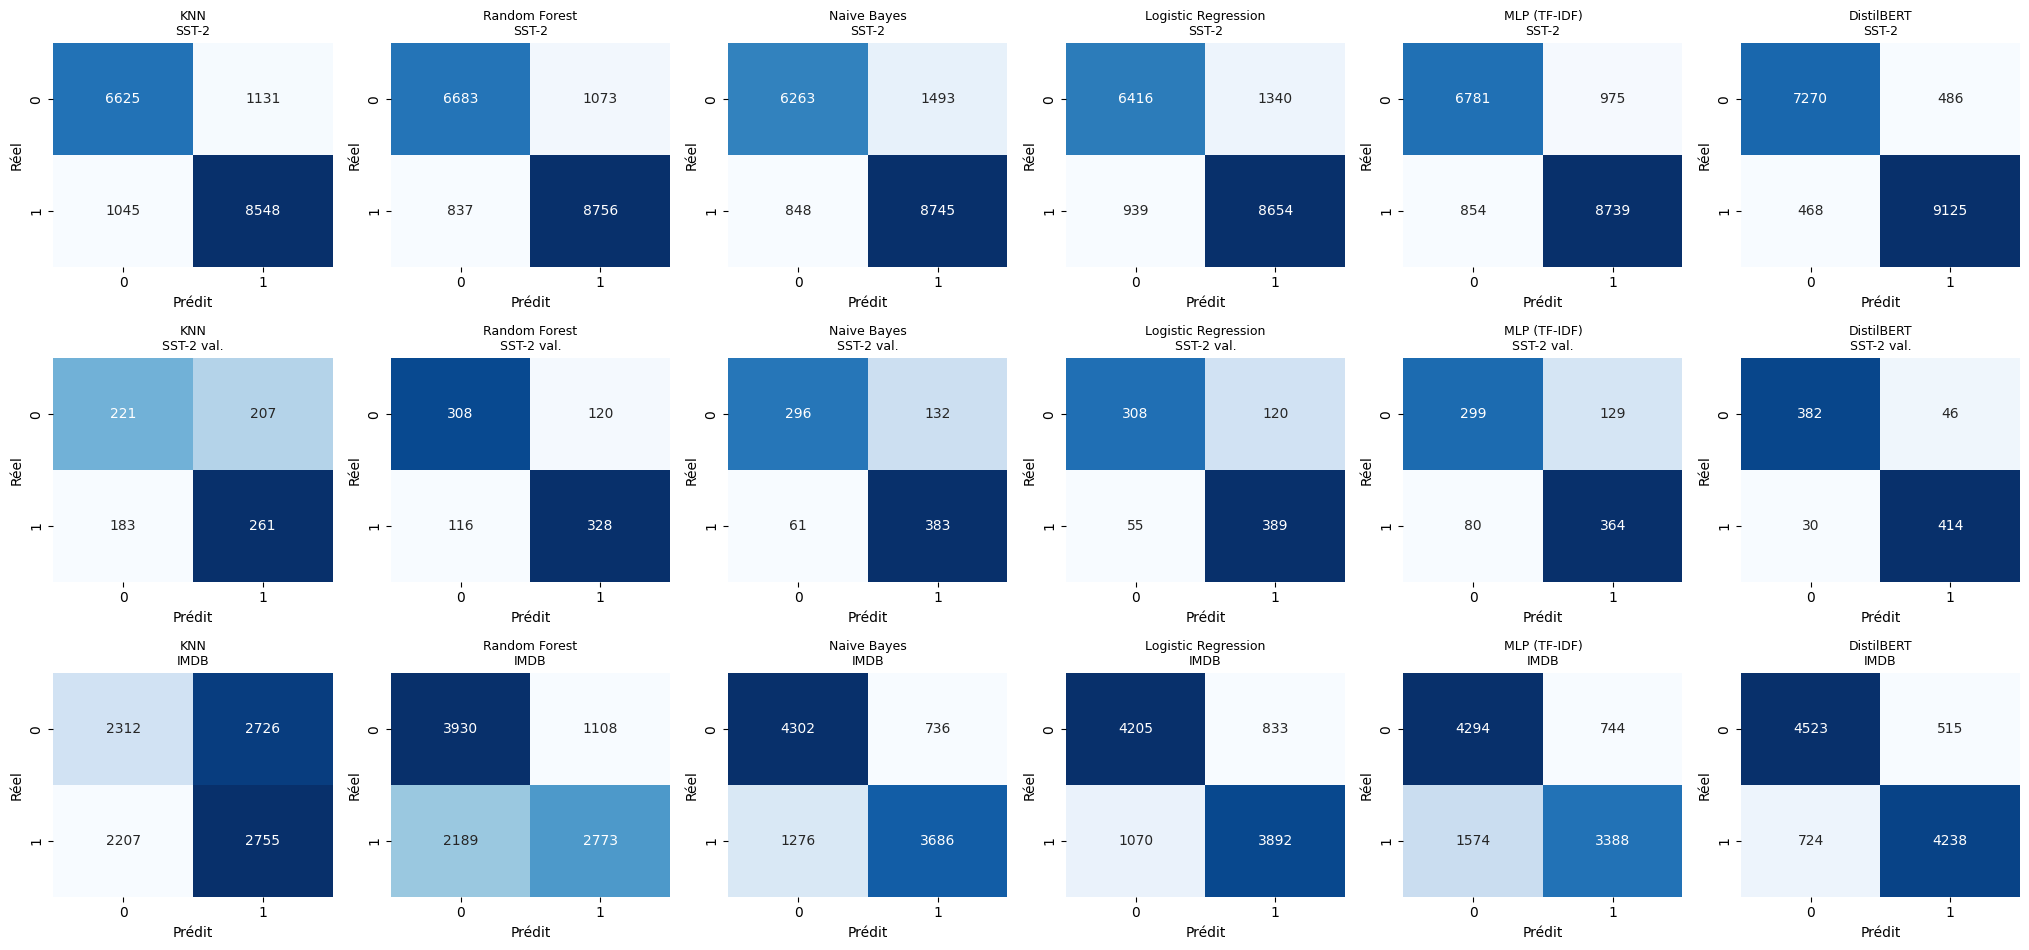

In [14]:
fig, axes = plt.subplots(len(Y), len(ALL_MODELS), figsize=(3.4 * len(ALL_MODELS), 3.2 * len(Y)))
for i, ds in enumerate(Y):
    for j, name in enumerate(ALL_MODELS):
        cm = confusion_matrix(Y[ds], preds[(name, ds)], labels=[0, 1])
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[i, j])
        axes[i, j].set_title(f"{name}\n{ds}", fontsize=9)
        axes[i, j].set_xlabel("Prédit")
        axes[i, j].set_ylabel("Réel")
plt.tight_layout()
plt.show()

### 9.2 Significativité : McNemar exact avec correction de Holm

Les nouvelles approches sont comparées sur les **mêmes exemples** : on ne compte que les exemples où les deux modèles ne donnent pas le même résultat. Les comparaisons choisies sont :
- MLP contre Logistic Regression (même représentation, meilleur modèle classique de l'article sur IMDB) ;
- DistilBERT contre Logistic Regression ;
- DistilBERT contre MLP.

Soit 3 comparaisons × 3 jeux de test = 9 tests, corrigés ensemble par la méthode de Holm.

Attention : sur la validation SST-2 (872 phrases), seules des différences supérieures à environ 2 points sont détectables ; une p-value élevée ne prouve pas l'absence d'effet.

In [15]:
def mcnemar_exact(y, pred_1, pred_2):
    ok1, ok2 = (pred_1 == y), (pred_2 == y)
    only1 = int((ok1 & ~ok2).sum())
    only2 = int((~ok1 & ok2).sum())
    n = only1 + only2
    p = binomtest(only1, n, 0.5).pvalue if n > 0 else 1.0
    return only1, only2, p

PAIRS = [
    ("MLP (TF-IDF)", "Logistic Regression"),
    ("DistilBERT", "Logistic Regression"),
    ("DistilBERT", "MLP (TF-IDF)"),
]

rows = []
for m1, m2 in PAIRS:
    for ds in Y:
        o1, o2, p = mcnemar_exact(Y[ds], preds[(m1, ds)], preds[(m2, ds)])
        rows.append({"Modèle 1": m1, "Modèle 2": m2, "Dataset": ds,
                     "Seul M1 correct": o1, "Seul M2 correct": o2, "p-value": p})

results_mcnemar = pd.DataFrame(rows)
results_mcnemar["p Holm"] = multipletests(results_mcnemar["p-value"], method="holm")[1]
results_mcnemar["Significatif (Holm, 5 %)"] = results_mcnemar["p Holm"] < 0.05
display(results_mcnemar.round(4))

,Modèle 1,Modèle 2,Dataset,Seul M1 correct,Seul M2 correct,p-value,p Holm,"Significatif (Holm, 5 %)"
0,MLP (TF-IDF),Logistic Regression,SST-2,997,547,0.000,0.000,True
1,MLP (TF-IDF),Logistic Regression,SST-2 val.,41,75,0.002,0.002,True
2,MLP (TF-IDF),Logistic Regression,IMDB,506,921,0.000,0.000,True
3,DistilBERT,Logistic Regression,SST-2,1742,417,0.000,0.000,True
4,DistilBERT,Logistic Regression,SST-2 val.,133,34,0.000,0.000,True
5,DistilBERT,Logistic Regression,IMDB,1242,578,0.000,0.000,True
6,DistilBERT,MLP (TF-IDF),SST-2,1321,446,0.000,0.000,True
7,DistilBERT,MLP (TF-IDF),SST-2 val.,165,32,0.000,0.000,True
8,DistilBERT,MLP (TF-IDF),IMDB,1646,567,0.000,0.000,True


## 10. Phrases contrôlées (illustratif)

Ce mini-test ne remplace pas une évaluation sur un jeu représentatif. Les modèles TF-IDF reçoivent le texte prétraité comme dans l'article (donc `not` est supprimé) ; DistilBERT reçoit le texte brut. Les emojis sont absents des données d'entraînement : DistilBERT peut les traiter comme des tokens inconnus, il ne faut donc pas en tirer de conclusion générale.

In [16]:
controlled_examples = [
    "I am happy",
    "I am not happy",
    "This movie is good",
    "This movie is not good",
    "I don't like it",
    "The film was bad",
    "The film was not bad",
    "I really love this movie 😊",
    "I really hate this movie 😡",
    "I'm not happy 😞",
]

def proba_sklearn(model, texts):
    return model.predict_proba(tfidf_original.transform([preprocess_original(t) for t in texts]))[:, 1]

def proba_bert(texts):
    m = trainer.model
    m.eval()
    enc = tokenizer(texts, padding=True, truncation=True, max_length=128, return_tensors="pt").to(m.device)
    with torch.no_grad():
        logits = m(**enc).logits
    return torch.softmax(logits.float(), dim=-1)[:, 1].cpu().numpy()

controlled = pd.DataFrame({
    "Texte": controlled_examples,
    "Logistic Regression": proba_sklearn(models_article["Logistic Regression"], controlled_examples),
    "MLP (TF-IDF)": proba_sklearn(mlp, controlled_examples),
    "DistilBERT": proba_bert(controlled_examples),
}).set_index("Texte")

print("P(positif) par modèle")
display(controlled.round(3))

P(positif) par modèle


,Logistic Regression,MLP (TF-IDF),DistilBERT
Texte,,,
I am happy,0.914,1.000,0.999
I am not happy,0.914,1.000,0.004
This movie is good,0.929,0.825,0.998
This movie is not good,0.929,0.825,0.004
I don't like it,0.408,0.889,0.014
The film was bad,0.029,0.172,0.004
The film was not bad,0.029,0.172,0.994
I really love this movie 😊,0.872,0.971,0.998
I really hate this movie 😡,0.144,0.016,0.007


## 11. Temps d'entraînement

In [17]:
display(pd.Series(timings, name="Temps d'entraînement (s)").round(1).to_frame())

,Temps d'entraînement (s)
KNN,0.0
Random Forest,14.4
Naive Bayes,0.0
Logistic Regression,0.4
MLP (TF-IDF),198.1
DistilBERT,135.4


## 12. Sauvegarde sur Google Drive (facultatif, utile pour l'interface finale)

In [19]:
from google.colab import drive
import os

drive.mount("/content/drive")
OUTPUT_DIR = "/content/drive/MyDrive/sentiment_project_v2"
os.makedirs(OUTPUT_DIR, exist_ok=True)

joblib.dump(tfidf_original, f"{OUTPUT_DIR}/tfidf_original.joblib")
for name, model in models_article.items():
    joblib.dump(model, f"{OUTPUT_DIR}/model_{name.lower().replace(' ', '_')}.joblib")
joblib.dump(mlp, f"{OUTPUT_DIR}/model_mlp.joblib")

trainer.save_model(f"{OUTPUT_DIR}/distilbert_sst2")
tokenizer.save_pretrained(f"{OUTPUT_DIR}/distilbert_sst2")

results_all.to_csv(f"{OUTPUT_DIR}/results_all_models.csv", index=False)
results_mcnemar.to_csv(f"{OUTPUT_DIR}/results_mcnemar_holm.csv", index=False)
controlled.to_csv(f"{OUTPUT_DIR}/controlled_predictions.csv")
pd.Series(timings).to_csv(f"{OUTPUT_DIR}/timings.csv")

print("Fichiers sauvegardés :", os.listdir(OUTPUT_DIR))

Mounted at /content/drive


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Fichiers sauvegardés : ['tfidf_original.joblib', 'model_knn.joblib', 'model_random_forest.joblib', 'model_naive_bayes.joblib', 'model_logistic_regression.joblib', 'model_mlp.joblib', 'distilbert_sst2', 'results_all_models.csv', 'results_mcnemar_holm.csv', 'controlled_predictions.csv', 'timings.csv']


## 13. Points à discuter dans le compte rendu

1. Comparer les 4 modèles reproduits aux valeurs publiées. Le F1 du KNN sur IMDB (0,35 dans l'article) doit être interprété avec le tableau de la section 6.2 (part de prédictions positives).
2. Expliquer l'écart entre SST-2 (split aléatoire) et SST-2 validation officielle : les sous-phrases communes au train et au test rendent le split aléatoire optimiste.
3. Décrire la généralisation de SST-2 vers IMDB (phrases courtes contre critiques longues : décalage de domaine).
4. **MLP contre Logistic Regression** : même TF-IDF, seul le classifieur change. Utiliser McNemar (Holm) pour dire si l'écart est significatif.
5. **DistilBERT contre les modèles TF-IDF** : l'écart combine classifieur et représentation (texte brut, contexte, pré-entraînement). Ne pas l'attribuer au seul « deep learning ». Mentionner aussi la troncature à 256 tokens sur IMDB et le coût (temps, GPU).
6. Phrases contrôlées : illustratives seulement ; les emojis ne sont présents ni dans les données ni dans le TF-IDF.
7. L'article ne précise pas tous les paramètres (TF-IDF, hyperparamètres au-delà de ceux cités) : cette reproduction suit sa structure et ses paramètres explicites, sans garantie d'identité exacte. Les hyperparamètres du MLP et de DistilBERT ont été fixés a priori, sans réglage sur les jeux de test.